In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from IPython.display import display

sns.set_theme(style="whitegrid")

df = pd.read_csv("/content/train.csv")

print("Dataset loaded successfully.")
print("Dataset shape (rows, columns):", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape (rows, columns): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
display(df.tail())
print("Dataset name: Titanic Passenger Dataset")
print("File type: CSV")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


Dataset name: Titanic Passenger Dataset
File type: CSV
Number of rows: 891
Number of columns: 12


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nData types:")
display(df.dtypes.to_frame("Data Type"))

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
\nData types:


,Data Type
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [4]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_columns = df.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

print("\\nNumerical summary:")
display(df[numerical_columns].describe().T)

print("\\nCategorical summary:")
display(df[categorical_columns].describe().T)

Numerical columns: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']
\nNumerical summary:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


\nCategorical summary:


,count,unique,top,freq
Name,891,891,"Dooley, Mr. Patrick",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


In [5]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent.round(2)
}).sort_values("Missing Count", ascending=False)

display(missing_report)
print("Columns with no missing values:")
print(missing_report[missing_report["Missing Count"] == 0].index.tolist())

,Missing Count,Missing Percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


Columns with no missing values:
['PassengerId', 'Name', 'Pclass', 'Survived', 'Sex', 'Parch', 'SibSp', 'Fare', 'Ticket']


In [6]:
clean_df = df.copy()

age_median = clean_df["Age"].median()
embarked_mode = clean_df["Embarked"].mode()[0]

clean_df["Age"] = clean_df["Age"].fillna(age_median)
clean_df["Embarked"] = clean_df["Embarked"].fillna(embarked_mode)

if "Cabin" in clean_df.columns:
    clean_df = clean_df.drop(columns=["Cabin"])

print("Median used for Age:", age_median)
print("Mode used for Embarked:", embarked_mode)
print("\\nMissing values after treatment:")
display(clean_df.isnull().sum().to_frame("Remaining Missing Values"))

Median used for Age: 28.0
Mode used for Embarked: S
\nMissing values after treatment:


,Remaining Missing Values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [7]:

duplicate_count = clean_df.duplicated().sum()
print("Duplicate rows before removal:", duplicate_count)

clean_df = clean_df.drop_duplicates().copy()

# Remove accidental leading/trailing spaces from text categories.
for col in clean_df.select_dtypes(include="object").columns:
    clean_df[col] = clean_df[col].str.strip()

# Standardise the case of the Sex category.
if "Sex" in clean_df.columns:
    clean_df["Sex"] = clean_df["Sex"].str.lower()

print("Duplicate rows after removal:", clean_df.duplicated().sum())
print("\\nUnique values in categorical columns:")
for col in clean_df.select_dtypes(include="object").columns:
    print(f"{col}: {clean_df[col].unique()[:15]}")

Duplicate rows before removal: 0
Duplicate rows after removal: 0
\nUnique values in categorical columns:
Name: ['Braund, Mr. Owen Harris'
 'Cumings, Mrs. John Bradley (Florence Briggs Thayer)'
 'Heikkinen, Miss. Laina' 'Futrelle, Mrs. Jacques Heath (Lily May Peel)'
 'Allen, Mr. William Henry' 'Moran, Mr. James' 'McCarthy, Mr. Timothy J'
 'Palsson, Master. Gosta Leonard'
 'Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)'
 'Nasser, Mrs. Nicholas (Adele Achem)' 'Sandstrom, Miss. Marguerite Rut'
 'Bonnell, Miss. Elizabeth' 'Saundercock, Mr. William Henry'
 'Andersson, Mr. Anders Johan' 'Vestrom, Miss. Hulda Amanda Adolfina']
Sex: ['male' 'female']
Ticket: ['A/5 21171' 'PC 17599' 'STON/O2. 3101282' '113803' '373450' '330877'
 '17463' '349909' '347742' '237736' 'PP 9549' '113783' 'A/5. 2151'
 '347082' '350406']
Embarked: ['S' 'C' 'Q']


In [8]:
print("Updated numerical summary:")
display(clean_df.select_dtypes(include=np.number).describe().T)

print("\\nPassenger count by sex:")
display(clean_df["Sex"].value_counts().to_frame("Count"))

print("\\nPassenger count by embarkation port:")
display(clean_df["Embarked"].value_counts().to_frame("Count"))

Updated numerical summary:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,891.0,29.361582,13.019697,0.42,22.0000,28.0000,35.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


\nPassenger count by sex:


,Count
Sex,
male,577
female,314


\nPassenger count by embarkation port:


,Count
Embarked,
S,646
C,168
Q,77


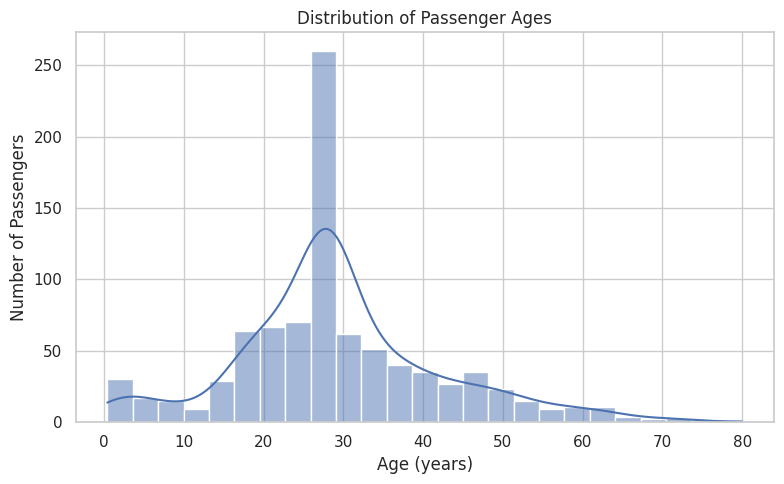

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(data=clean_df, x="Age", bins=25, kde=True)
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

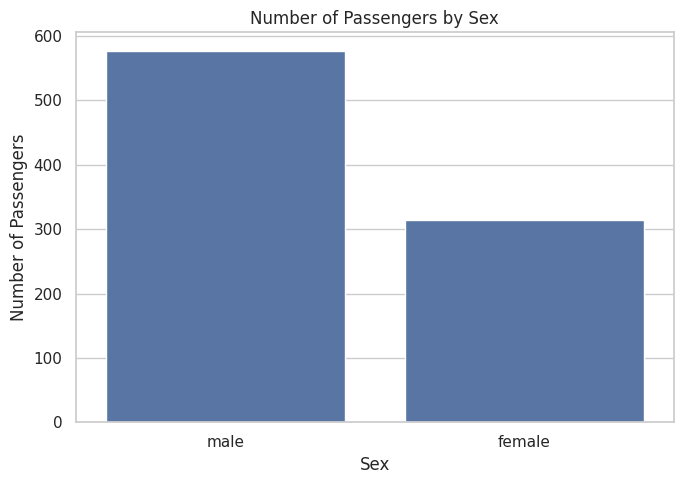

In [10]:
plt.figure(figsize=(7, 5))
sns.countplot(data=clean_df, x="Sex")
plt.title("Number of Passengers by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

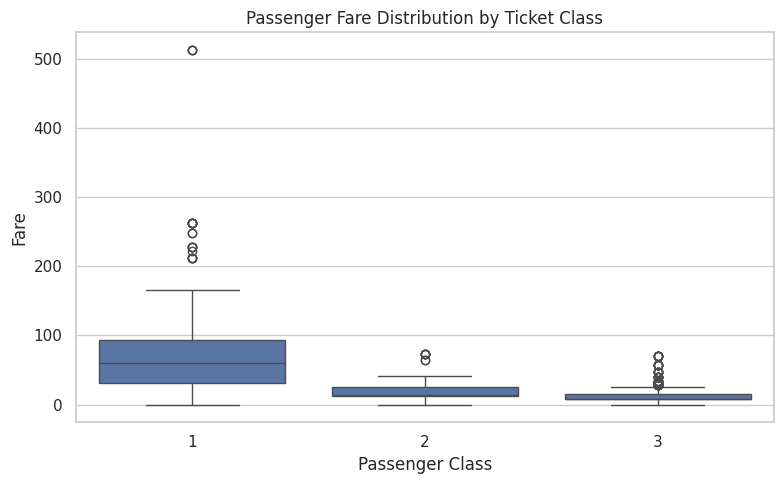

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_df, x="Pclass", y="Fare")
plt.title("Passenger Fare Distribution by Ticket Class")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

In [12]:
# Start from cleaned data and remove fields not selected as model features.
prepared = clean_df.drop(columns=["Name", "Ticket"], errors="ignore").copy()

# Keep PassengerId as an identifier, and Survived as a future target.
# One-hot encode nominal categorical input columns.
categorical_to_encode = [c for c in ["Sex", "Embarked", "Pclass"] if c in prepared.columns]

prepared = pd.get_dummies(
    prepared,
    columns=categorical_to_encode,
    drop_first=False,
    dtype=int
)

print("Categorical columns encoded:", categorical_to_encode)
print("Shape after encoding:", prepared.shape)
display(prepared.head())

Categorical columns encoded: ['Sex', 'Embarked', 'Pclass']
Shape after encoding: (891, 14)


,PassengerId,Survived,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
0,1,0,22.0,1,0,7.2500,0,1,0,0,1,0,0,1
1,2,1,38.0,1,0,71.2833,1,0,1,0,0,1,0,0
2,3,1,26.0,0,0,7.9250,1,0,0,0,1,0,0,1
3,4,1,35.0,1,0,53.1000,1,0,0,0,1,1,0,0
4,5,0,35.0,0,0,8.0500,0,1,0,0,1,0,0,1


In [13]:
target_column = "Survived"
id_columns = ["PassengerId"] if "PassengerId" in prepared.columns else []

numeric_feature_columns = [
    c for c in ["Age", "SibSp", "Parch", "Fare"]
    if c in prepared.columns
]

# Create a training index only to learn scaling parameters.
train_indices, _ = train_test_split(
    prepared.index,
    test_size=0.20,
    random_state=42,
    stratify=prepared[target_column] if target_column in prepared.columns else None
)

scaler = StandardScaler()
scaler.fit(prepared.loc[train_indices, numeric_feature_columns])

prepared[numeric_feature_columns] = scaler.transform(
    prepared[numeric_feature_columns]
)

print("Scaling method: StandardScaler")
print("Scaled numerical features:", numeric_feature_columns)
print("Identifier not scaled:", id_columns)
print("Target not scaled:", target_column)
display(prepared.head())

Scaling method: StandardScaler
Scaled numerical features: ['Age', 'SibSp', 'Parch', 'Fare']
Identifier not scaled: ['PassengerId']
Target not scaled: Survived


,PassengerId,Survived,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
0,1,0,-0.572716,0.478335,-0.466183,-0.511601,0,1,0,0,1,0,0,1
1,2,1,0.655652,0.478335,-0.466183,0.821722,1,0,1,0,0,1,0,0
2,3,1,-0.265624,-0.465084,-0.466183,-0.497546,1,0,0,0,1,0,0,1
3,4,1,0.425333,0.478335,-0.466183,0.443103,1,0,0,0,1,1,0,0
4,5,0,0.425333,-0.465084,-0.466183,-0.494943,0,1,0,0,1,0,0,1


In [14]:
print("Final dataset shape:", prepared.shape)
print("\\nRemaining missing values:", int(prepared.isnull().sum().sum()))
print("Remaining duplicate rows:", int(prepared.duplicated().sum()))

display(prepared.head())

output_file = "Prepared_Titanic_Dataset.csv"
prepared.to_csv(output_file, index=False)
print(f"Prepared dataset saved as: {output_file}")

Final dataset shape: (891, 14)
\nRemaining missing values: 0
Remaining duplicate rows: 0


,PassengerId,Survived,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
0,1,0,-0.572716,0.478335,-0.466183,-0.511601,0,1,0,0,1,0,0,1
1,2,1,0.655652,0.478335,-0.466183,0.821722,1,0,1,0,0,1,0,0
2,3,1,-0.265624,-0.465084,-0.466183,-0.497546,1,0,0,0,1,0,0,1
3,4,1,0.425333,0.478335,-0.466183,0.443103,1,0,0,0,1,1,0,0
4,5,0,0.425333,-0.465084,-0.466183,-0.494943,0,1,0,0,1,0,0,1


Prepared dataset saved as: Prepared_Titanic_Dataset.csv
